# 08 · Simulación de salidas y su evaluación

**Términos que se usan en este notebook:** [simulación de salidas](../docs/entrega_1/glosario.md) (reconstruir muchos futuros posibles de un año repitiendo trozos del pasado de la acción y contar en cuántos el precio llega al nivel de salida), **origen** (cada fecha desde la que se simula, con datos hasta ese día), [Brier](../docs/entrega_1/glosario.md) (error cuadrático medio entre la probabilidad prometida y lo que ocurrió; menor es mejor), **BSS o Brier skill score** (`1 − Brier(simulación) / Brier(referencia)`: positivo si la simulación se equivoca menos que la referencia), [calibración](../docs/entrega_1/glosario.md) (si cuando la simulación promete 60 % el precio llegó cerca del 60 % de las veces), [AUC](../docs/entrega_1/glosario.md), [brecha](../docs/entrega_1/glosario.md), [IC](../docs/entrega_1/glosario.md) y [bootstrap por bloques de fechas](../docs/entrega_1/glosario.md).

**Qué se evalúa.** Cada nivel de salida del usuario recibe una probabilidad: *si el futuro repitiera trozos del pasado de esta acción, ¿en qué fracción de los años simulados el cierre semanal llega al nivel?* Esto **no es un pronóstico**: es lo que habría pasado bajo un supuesto muy concreto. La pregunta de este notebook es qué tan confiable ha sido ese número cuando se comparó con lo que ocurrió después, en la misma partición cronológica que el modelo técnico (validación y prueba; el entrenamiento solo fija la referencia). Aquí no hay H0/H1: se **evalúa un procedimiento**, no se contrasta una hipótesis del negocio.

## 1. El método y su supuesto

**Remuestreo por bloques de semanas.** Se toman los retornos semanales de la acción hasta la fecha del origen. Para armar un año simulado se pegan 5 trozos de 12 semanas seguidas, elegidos al azar con reemplazo, y se recorta a 52 semanas; con esos retornos se reconstruye el precio semana a semana desde el precio actual. Se repite 2 000 veces y la **probabilidad** es la fracción de años simulados en que algún cierre semanal llega al nivel. Se usan **trozos seguidos** y no semanas sueltas porque la turbulencia viene en rachas (después de una semana muy agitada suele venir otra; notebook 03): copiar trozos conserva esas rachas.

**El XLP (el fondo del sector) entra por las fechas.** Los trozos se eligen sobre las semanas en que existen la acción y el XLP, y la misma elección vale para ambos, de modo que la relación entre la acción y su sector se conserva por construcción. Una advertencia honesta: la probabilidad solo usa los retornos de la acción; el XLP determina qué semanas existen y deja listo el remuestreo conjunto para extensiones, pero no cambia la cifra.

**Supuesto que cambia.** Al pegar trozos se supone que los trozos son **independientes entre sí** (el pasado reciente no condiciona qué trozo viene después) y que el comportamiento histórico de la acción se repite. El bloque de 12 semanas mitiga lo primero (la dependencia más fuerte vive dentro del trozo). Lo segundo es justo lo que el notebook 06 puso en duda (la volatilidad cambió entre conjuntos), por eso aquí se **mide** en lugar de suponerlo.

**Qué mide el rango de `simular_salidas`.** `ic_lo` e `ic_hi` son el **error de simulación**: cuánto cambiaría la probabilidad si se repitiera la simulación con otras 2 000 réplicas (`prob ± 1,96 · sd(20 sublotes) / √20`). No es la incertidumbre del modelo ni del futuro; cuánto confiar en la probabilidad se lee en la calibración de las secciones 5 y 6.

In [1]:
import json, sys, time, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score
sys.path.insert(0, "."); import comunes as cm      # nbconvert ejecuta el kernel en notebooks/, donde está comunes.py
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 30)
T0 = time.time()

# --- Constantes de esta tarea: se escribieron ANTES de evaluar y no se tocan después ---
K_EVAL = (0.5, 1.0, 1.5)     # nivel de evaluación = precio_t · exp(+k · σ52_sem · √h): espejo de la etiqueta de entrada (precio · exp(−k · σ · √N))
H_EVAL = 52                  # semanas (= SIM_HORIZONTE_SEMANAS)
MIN_HIST_SEM_SIM = 104       # semanas de historia mínima (2 años; convención del proyecto)
PASO_ORIGEN_SEM = 4          # un origen de evaluación cada 4 semanas (menos solape y menos costo)
BLOQUE_IC_FECHAS = 13        # orígenes por bloque en el IC de la evaluación (13 × 4 = 52 semanas: el solape de un resultado)
N_SUBLOTES_IC = 20           # sublotes de simulación para el error de simulación de simular_salidas
CRITERIO_CALIB = 0.05        # error de calibración medio (|prob prometida − frecuencia observada|, ponderado por grupo): referencia descriptiva, sin decisión
# Las de la simulación viven en comunes.py y se comprueban aquí para que no puedan divergir:
assert (cm.SIM_HORIZONTE_SEMANAS, cm.SIM_BLOQUE_SEMANAS, cm.SIM_REPS, cm.SIM_REPS_RF11) == (H_EVAL, 12, 2000, 500)
assert (cm.MIN_HIST_SEM_SIM, cm.N_SUBLOTES_IC) == (MIN_HIST_SEM_SIM, N_SUBLOTES_IC)
CONJUNTOS_EVAL = ["validacion", "prueba"]
KS = [str(float(k)) for k in K_EVAL]                 # claves de los JSON: "0.5", "1.0", "1.5"
SUBPERIODOS = {"2010–2012": (2009, 2012), "2013–2019": (2013, 2019), "2020–2021": (2020, 2021), "2022+": (2022, 2100)}   # mismos rótulos que nb06 y nb07
fm = lambda n: f"{n:,}".replace(",", " ")            # miles con espacio, como en el texto
res = {}                                              # cifras que se guardan en data/resultados/nb08.json
cm.DIR_ASSETS_E2.mkdir(parents=True, exist_ok=True)

## 2. Datos

Precio semanal **ajustado por dividendos** (retorno total que recibe el inversor) de las 21 acciones y del XLP, desde la instantánea fechada. Los retornos son logaritmos del cociente entre una semana y la anterior.

In [2]:
# Precio semanal AJUSTADO por dividendos (retorno total del inversor): 21 acciones + XLP (el SPY de la instantánea no se usa aquí)
sem = cm.a_ancho(cm.cargar_snapshot("precios_semanales"))
px = sem[cm.tickers()]; px_xlp = sem["XLP"]
r = np.log(px).diff(); r_xlp = np.log(px_xlp).diff()          # log-retornos semanales
assert px.shape[1] == 21 and px_xlp.notna().all()
cal = sem.index                                                # calendario semanal COMPLETO (fechas únicas)
sep = np.diff(cal.values) / np.timedelta64(1, "D")
print(f"semanas: {len(cal)} ({cal[0].date()} a {cal[-1].date()}) · separación entre semanas: mín {sep.min():.0f}, mediana {np.median(sep):.0f}, máx {sep.max():.0f} días")
print(f"vacíos en los precios de las 21 acciones: {int(px.isna().sum().sum())} · semanas con retorno por acción: mín {int(r.notna().sum().min())}")
print("\nTamaño de los retornos semanales (log): desviación media de las 21 acciones =", f"{r.std().mean():.4f}", "· XLP =", f"{r_xlp.std():.4f}")

semanas: 928 (2009-01-05 a 2026-10-12) · separación entre semanas: mín 7, mediana 7, máx 7 días
vacíos en los precios de las 21 acciones: 0 · semanas con retorno por acción: mín 927

Tamaño de los retornos semanales (log): desviación media de las 21 acciones = 0.0298 · XLP = 0.0182


**Lectura.** Hay 928 semanas (2009-01-05 a 2026-10-12), todas separadas por 7 días, sin vacíos en los precios de las 21 acciones y con al menos 927 retornos por acción. La desviación semanal media de las acciones es 0,0298 y la del XLP 0,0182: el sector se mueve menos que una acción típica, como es de esperar de una canasta.

## 3. Un ejemplo: 5 trayectorias simuladas de KO

Con los datos de KO y del XLP hasta 2019-12-31 se arman 5 años simulados y se mira cuáles llegan a un nivel 15 % por encima del precio.

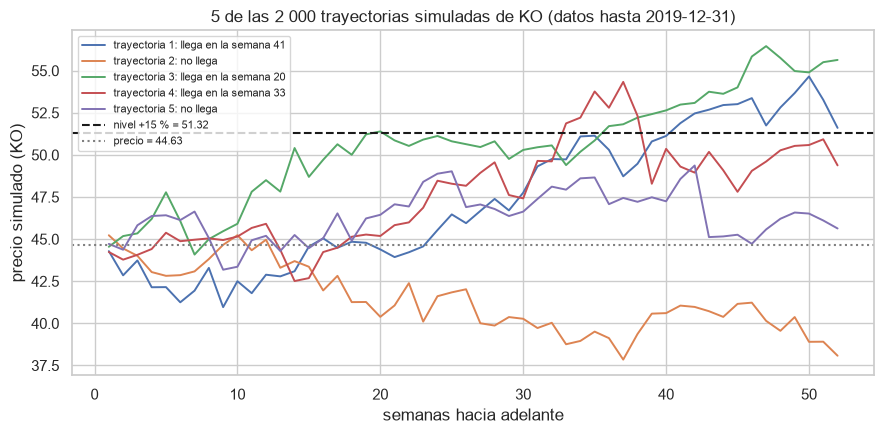

semanas comunes acción-XLP disponibles: 573
máximo de cada trayectoria / precio: [1.225, 1.014, 1.265, 1.217, 1.106]


In [3]:
# Ejemplo ilustrativo: 5 trayectorias de KO a 52 semanas, con datos hasta 2019-12-31 y un nivel a +15 % sobre el precio.
# (Es el mismo remuestreo de simular_salidas, escrito aquí para poder DIBUJAR las trayectorias; la función solo devuelve el resumen.)
fecha_ej = pd.Timestamp("2019-12-31")
ra = r["KO"].loc[:fecha_ej].dropna(); rx = r_xlp.loc[:fecha_ej].dropna()
P_ej = float(px["KO"].loc[:fecha_ej].iloc[-1]); nivel_ej = P_ej * 1.15
datos = pd.concat([ra, rx], axis=1, keys=["accion", "xlp"]).dropna()
n_d = len(datos); bl = cm.SIM_BLOQUE_SEMANAS; nbl = int(np.ceil(H_EVAL / bl))
rng = np.random.default_rng(cm.SEMILLA)
ini = rng.integers(0, n_d - bl + 1, size=(5, nbl))                       # dónde empieza cada bloque (los mismos índices valen para acción y XLP)
idx = (ini[:, :, None] + np.arange(bl)).reshape(5, -1)[:, :H_EVAL]
tray = P_ej * np.exp(np.cumsum(datos["accion"].to_numpy()[idx], axis=1))
fig, ax = plt.subplots(figsize=(9, 4.5))
for i in range(5):
    toca = bool((tray[i] >= nivel_ej).any())
    ax.plot(range(1, H_EVAL + 1), tray[i], lw=1.4, label=f"trayectoria {i + 1}: " + (f"llega en la semana {int(np.argmax(tray[i] >= nivel_ej)) + 1}" if toca else "no llega"))
ax.axhline(nivel_ej, color="k", ls="--", label=f"nivel +15 % = {nivel_ej:.2f}"); ax.axhline(P_ej, color="gray", ls=":", label=f"precio = {P_ej:.2f}")
ax.set_xlabel("semanas hacia adelante"); ax.set_ylabel("precio simulado (KO)"); ax.set_title("5 de las 2 000 trayectorias simuladas de KO (datos hasta 2019-12-31)")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.savefig(cm.DIR_ASSETS_E2 / "nb08_trayectorias.png", dpi=130); plt.show()
print(f"semanas comunes acción-XLP disponibles: {n_d}")
print("máximo de cada trayectoria / precio:", np.round(tray.max(axis=1) / P_ej, 3).tolist())

**Lectura.** De las 5 trayectorias, 3 llegan al nivel de +15 % (sus máximos son 1,225, 1,265 y 1,217 veces el precio) y 2 no (1,014 y 1,106). Se ve la idea del método: cada trayectoria es un año posible hecho con trozos reales del pasado, y la probabilidad es simplemente la fracción de ellas que cruza la línea punteada negra. Con 2 000 en lugar de 5, KO llega al +15 % en 53,8 % de los años simulados (sección 4). Hay 573 semanas comunes de KO y XLP hasta esa fecha para elegir trozos.

## 4. Verificación de `simular_salidas`

Antes de evaluar, se comprueba la función con KO y su XLP hasta 2019-12-31 y tres niveles (+5 %, +15 %, +30 %): que las probabilidades bajen al alejar el nivel, que el rango contenga la estimación, que con poca historia no falle, que sea reproducible, que un nivel que ya se alcanzó dé 1, que el error de simulación sea el correcto (10 semillas contra una referencia de 20 000 réplicas) y cuánto tarda (la API la llama en cada petición).

In [4]:
# Verificación de simular_salidas con KO y su XLP hasta 2019-12-31 (tres niveles: +5 %, +15 %, +30 %)
niv_ej = [P_ej * 1.05, P_ej * 1.15, P_ej * 1.30]
t1 = time.perf_counter(); sim = cm.simular_salidas(ra, rx, P_ej, niv_ej); seg_primera = time.perf_counter() - t1
print(sim.to_string(index=False))
ok_orden = bool(sim["prob"].is_monotonic_decreasing and sim["prob"].between(0, 1, inclusive="neither").all())
ok_ic = bool(((sim["ic_lo"] <= sim["prob"]) & (sim["prob"] <= sim["ic_hi"])).all())
print(f"\nprobabilidades decrecientes en (0, 1): {ok_orden} · ic_lo ≤ prob ≤ ic_hi: {ok_ic}")
# Poca historia: con 50 semanas devuelve vacíos (nan) sin lanzar excepción
corto = cm.simular_salidas(ra.iloc[:50], rx.iloc[:50], P_ej, niv_ej)
print(f"con 50 semanas: prob = {corto['prob'].tolist()} (sin excepción)")
# Determinismo: la misma semilla da exactamente el mismo resultado; otra semilla cambia las probabilidades (un poco)
igual = cm.simular_salidas(ra, rx, P_ej, niv_ej).equals(sim); otra = cm.simular_salidas(ra, rx, P_ej, niv_ej, semilla=7)
print(f"misma semilla → idéntico: {igual} · otra semilla: {np.round(otra['prob'].to_numpy(), 3).tolist()}")
# Un nivel por debajo o igual al precio: ya alcanzado (la API lo valida antes)
ya = cm.simular_salidas(ra, rx, P_ej, [P_ej * 0.9, P_ej])
print("niveles ≤ precio:", ya[["prob", "semanas_mediana"]].values.tolist())
# Error de simulación: con 10 semillas, |prob(2000 réplicas) − prob_ref(20 000)| ≤ 3 × max(error de simulación, piso binomial)
ref = cm.simular_salidas(ra, rx, P_ej, niv_ej, reps=20000, semilla=999)
p_cl = ref["prob"].clip(0.01, 0.99); piso = np.sqrt(p_cl * (1 - p_cl) / cm.SIM_REPS)
cumple, max_ratio = [], 0.0
for s in range(10):
    q = cm.simular_salidas(ra, rx, P_ej, niv_ej, semilla=s)
    es = (q["ic_hi"] - q["ic_lo"]) / (2 * 1.96)
    cota = 3 * np.maximum(es, piso)
    cumple.append(bool((np.abs(q["prob"] - ref["prob"]) <= cota).all())); max_ratio = max(max_ratio, float((np.abs(q["prob"] - ref["prob"]) / cota * 3).max()))
print(f"criterio con 10 semillas (3 × error): cumple en {sum(cumple)} de 10 · mayor desviación = {max_ratio:.2f} errores de simulación")
print("referencia con 20 000 réplicas:", np.round(ref["prob"].to_numpy(), 4).tolist(), "· 2 000 réplicas (semilla 42):", np.round(sim["prob"].to_numpy(), 4).tolist())
# Tiempo de una llamada con 3 niveles (la API la hace en cada petición; Render gratuito tiene 0,1 CPU)
def tiempo(reps, veces=30):
    ts = []
    for _ in range(veces):
        t = time.perf_counter(); cm.simular_salidas(ra, rx, P_ej, niv_ej, reps=reps); ts.append(time.perf_counter() - t)
    return float(np.median(ts)), float(np.max(ts))
tm2000, tx2000 = tiempo(cm.SIM_REPS); tm500, tx500 = tiempo(cm.SIM_REPS_RF11)
print(f"\ntiempo de una llamada (3 niveles, mediana de 30): {tm2000 * 1000:.1f} ms con {cm.SIM_REPS} réplicas (máx {tx2000 * 1000:.1f} ms); {tm500 * 1000:.1f} ms con {cm.SIM_REPS_RF11} (máx {tx500 * 1000:.1f} ms)")
res["verificacion_funcion"] = {"ticker": "KO", "fecha": str(fecha_ej.date()), "niveles_pct": [5, 15, 30], "prob": sim["prob"].round(4).tolist(),
    "decrecientes_en_0_1": ok_orden, "ic_ordenado": ok_ic, "nan_con_50_semanas": bool(corto["prob"].isna().all()), "determinista": bool(igual),
    "semillas_dentro_de_3_errores": int(sum(cumple)), "prob_ref_20000": ref["prob"].round(4).tolist()}
res["tiempo_llamada_ms"] = {"reps_2000_mediana": round(tm2000 * 1000, 2), "reps_2000_max": round(tx2000 * 1000, 2),
                            "reps_500_mediana": round(tm500 * 1000, 2), "reps_500_max": round(tx500 * 1000, 2), "niveles": 3, "semanas_historia": int(len(datos))}

  nivel   prob  ic_lo  ic_hi  semanas_mediana
46.8601 0.8880 0.8750 0.9010          11.5000
51.3230 0.5380 0.5144 0.5616          30.0000
58.0173 0.1460 0.1360 0.1560          41.0000

probabilidades decrecientes en (0, 1): True · ic_lo ≤ prob ≤ ic_hi: True
con 50 semanas: prob = [nan, nan, nan] (sin excepción)
misma semilla → idéntico: True · otra semilla: [0.892, 0.558, 0.15]
niveles ≤ precio: [[1.0, 1.0], [1.0, 1.0]]
criterio con 10 semillas (3 × error): cumple en 10 de 10 · mayor desviación = 1.66 errores de simulación
referencia con 20 000 réplicas: [0.8903, 0.5548, 0.1492] · 2 000 réplicas (semilla 42): [0.888, 0.538, 0.146]

tiempo de una llamada (3 niveles, mediana de 30): 1.0 ms con 2000 réplicas (máx 1.3 ms); 0.5 ms con 500 (máx 0.6 ms)


**Lectura.** Las probabilidades son 0,888 (+5 %), 0,538 (+15 %) y 0,146 (+30 %): decrecientes y dentro de (0, 1), con `ic_lo ≤ prob ≤ ic_hi` (por ejemplo, 0,538 con rango 0,514 a 0,562). La semana mediana en que se cruza crece con la distancia: 11,5; 30 y 41. Con 50 semanas de historia devuelve vacío en las tres probabilidades sin lanzar excepción; con la misma semilla el resultado es idéntico; con niveles iguales o menores al precio devuelve probabilidad 1 y semana 1. La referencia de 20 000 réplicas da 0,8903; 0,5548 y 0,1492, y las 10 semillas de 2 000 réplicas quedan dentro de 3 errores de simulación en las 10 (la mayor desviación es 1,66 errores): el rango describe bien el ruido de repetir la simulación. **Tiempo:** una llamada con 3 niveles tarda alrededor de 1 ms con 2 000 réplicas y alrededor de 0,5 ms con 500 (cifras exactas en `nb08.json`, `tiempo_llamada_ms`; varían un poco entre ejecuciones), medido en este computador; Render gratuito tiene 0,1 CPU, así que se espera una cifra bastante mayor (no medida aquí), todavía de milisegundos o pocas decenas de milisegundos.

## 5. Evaluación sin mirar el futuro

**Diseño.** Para cada acción y cada fecha de origen (una cada 4 semanas) se calcula, con datos hasta ese día: el precio, la volatilidad `σ52_sem` (desviación de los últimos 52 retornos semanales) y tres niveles de salida a `k = 0,5; 1,0; 1,5` volatilidades anuales por encima del precio (`precio · exp(k · σ52_sem · √52)`, el espejo de la etiqueta de entrada). Se simula y se compara con lo que ocurrió: **y = 1** si algún cierre semanal de las 52 semanas siguientes llegó al nivel. El resultado real es lo único que mira al futuro. La función `evaluar_origen` hace todo esto y es **la misma que usa el bucle de evaluación**; cada origen usa `semilla = 42 + i` para no repetir los mismos números aleatorios.

**Prueba de ausencia de look-ahead.** Para 3 acciones y 5 orígenes cada una se ejecuta `evaluar_origen` con la serie original y con una serie cuyo futuro se corrompió (retornos posteriores al origen multiplicados por 10 y 20 semanas nuevas añadidas). Con la misma semilla, el precio, la volatilidad, los niveles y todas las columnas de la simulación deben ser idénticos.

In [5]:
def evaluar_origen(px_acc, px_xlp, t, ks=K_EVAL, h=H_EVAL, bloque=cm.SIM_BLOQUE_SEMANAS, reps=cm.SIM_REPS, semilla=cm.SEMILLA):
    """Todo lo que se calcula en el origen t. CORTA con .loc[:t] (≤ t, incluido t) antes de usar nada; el bucle de evaluación
    llama exactamente a esta función. Devuelve (precio, σ52_sem, niveles, tabla de simular_salidas)."""
    pa = px_acc.loc[:t].dropna(); pxl = px_xlp.loc[:t].dropna()
    ra_t = np.log(pa).diff().dropna(); rx_t = np.log(pxl).diff().dropna()      # log-retornos semanales hasta t
    P = float(pa.iloc[-1])
    sigma = float(ra_t.iloc[-52:].std(ddof=1)) if len(ra_t) >= 52 else np.nan  # σ52_sem: los últimos 52 retornos, no centrada
    niveles = P * np.exp(np.asarray(ks, dtype=float) * sigma * np.sqrt(h))
    out = cm.simular_salidas(ra_t, rx_t, P, list(niveles), semanas=h, bloque=bloque, reps=reps, semilla=semilla)
    return P, sigma, niveles, out

def corromper(serie, t, rng):
    """Misma serie hasta t; después de t los retornos se multiplican por 10 y se agregan 20 semanas nuevas (mundo futuro distinto)."""
    s = serie.dropna(); lp = np.log(s); rr = lp.diff()
    despues = np.exp(lp.loc[t] + (rr.loc[rr.index > t] * 10).cumsum())          # lo posterior a t, con retornos ×10
    extra_idx = pd.date_range(s.index[-1] + pd.Timedelta(days=7), periods=20, freq="7D")
    base = despues.iloc[-1] if len(despues) else s.iloc[-1]
    extra = pd.Series(base * np.exp(np.cumsum(rng.normal(0, 0.05, 20))), index=extra_idx)   # y 20 semanas nuevas
    return pd.concat([s.loc[:t], despues, extra])                               # hasta t, los valores ORIGINALES

# Prueba de ausencia de look-ahead: 3 tickers × 5 orígenes; el resultado en t debe ser idéntico con el futuro intacto o corrompido
rng_c = np.random.default_rng(123)
iguales, n_pruebas = [], 0
for tk in ["KO", "PG", "WMT"]:
    fechas_o = cal[150::120][:5]                                           # 5 orígenes repartidos entre ~2011 y ~2021
    for t in fechas_o:
        a = evaluar_origen(px[tk], px_xlp, t, semilla=cm.SEMILLA)
        b = evaluar_origen(corromper(px[tk], t, rng_c), corromper(px_xlp, t, rng_c), t, semilla=cm.SEMILLA)
        pack = lambda z: np.concatenate([[z[0], z[1]], z[2], z[3][["prob", "ic_lo", "ic_hi", "semanas_mediana"]].to_numpy().ravel()])
        iguales.append(bool(np.array_equal(pack(a), pack(b), equal_nan=True))); n_pruebas += 1
lookahead_sim_ok = bool(all(iguales))
print(f"origen igual con el futuro intacto y con el futuro corrompido (×10 y 20 semanas nuevas): {sum(iguales)} de {n_pruebas} (np.array_equal) → lookahead_sim_ok = {lookahead_sim_ok}")
# Control positivo: si la función SÍ mirara el futuro, la prueba lo detectaría (aquí se le pasa la serie corrompida SIN cortar en t)
t_c = fechas_o[2]; mala = corromper(px["WMT"], t_c, np.random.default_rng(1))
dif = evaluar_origen(mala, px_xlp, mala.index[-1], semilla=cm.SEMILLA)[3]["prob"].to_numpy()          # usa el último dato corrompido como "t"
base = evaluar_origen(px["WMT"], px_xlp, t_c, semilla=cm.SEMILLA)[3]["prob"].to_numpy()
print("control positivo (mirando el futuro corrompido las probabilidades cambian):", np.round(base, 3).tolist(), "→", np.round(dif, 3).tolist())
res["lookahead_sim_ok"] = lookahead_sim_ok

origen igual con el futuro intacto y con el futuro corrompido (×10 y 20 semanas nuevas): 15 de 15 (np.array_equal) → lookahead_sim_ok = True
control positivo (mirando el futuro corrompido las probabilidades cambian): [0.584, 0.222, 0.05] → [0.64, 0.27, 0.078]


**Lectura.** El resultado en el origen es idéntico en los 15 de 15 casos con `np.array_equal` (`lookahead_sim_ok = true`): ni el precio, ni σ52, ni los niveles, ni la probabilidad dependen de lo que pase después. Como control positivo, si a la función se le entrega la serie corrompida **sin cortar** en el origen, las probabilidades sí cambian (0,584; 0,222; 0,050 pasan a 0,640; 0,270; 0,078), así que la prueba es capaz de detectar una fuga.

## 6. Orígenes, conjuntos y brecha

La partición se asigna con `asignar_conjunto(..., brecha=52, unidad="semanas")` sobre el calendario semanal **completo**, antes de filtrar. La brecha de 52 semanas (la del horizonte de la simulación; la del SVM es de 60 sesiones, unas 12 semanas) hace que el resultado de un origen de entrenamiento o de validación no mire dentro del conjunto siguiente. Se excluyen y se cuentan los orígenes con poca historia (menos de 104 semanas de retornos) y los **censurados** (menos de 52 semanas futuras: no se pueden resolver).

In [6]:
# Orígenes: una fecha cada 4 semanas del calendario COMPLETO, para cada una de las 21 acciones.
conj_cal = pd.Series(cm.asignar_conjunto(pd.Series(cal), brecha=cm.SIM_HORIZONTE_SEMANAS, unidad="semanas").to_numpy(), index=cal)   # sobre el calendario completo, ANTES de filtrar
fechas_origen = cal[::PASO_ORIGEN_SEM]
filas, i = [], 0
t0 = time.time()
for tk in cm.tickers():
    p_tk = px[tk]; xl = px_xlp
    for t in fechas_origen:
        P, sigma, niveles, out = evaluar_origen(p_tk, xl, t, semilla=cm.SEMILLA + i)
        futuro = p_tk.loc[t:].iloc[1:H_EVAL + 1]                              # las 52 semanas SIGUIENTES: lo único que mira al futuro
        cens = len(futuro) < H_EVAL
        for k, nv, (_, o) in zip(K_EVAL, niveles, out.iterrows()):
            y = np.nan if cens else float(futuro.max() >= nv)
            filas.append((t, tk, float(k), P, sigma, nv, o["prob"], o["ic_lo"], o["ic_hi"], o["semanas_mediana"], y, cens, conj_cal[t]))
        i += 1
orig = pd.DataFrame(filas, columns=["fecha", "ticker", "k", "precio", "sigma52", "nivel", "prob", "ic_lo", "ic_hi", "semanas_mediana", "y", "censurado", "conjunto"])
orig["poca_historia"] = orig["prob"].isna()
print(f"orígenes simulados: {i} ({len(fechas_origen)} fechas × 21 acciones) · filas con k: {fm(len(orig))} · tiempo: {time.time() - t0:.0f} s")

orígenes simulados: 4872 (232 fechas × 21 acciones) · filas con k: 14 616 · tiempo: 6 s


In [7]:
# Antes / después: de todos los orígenes a los que se evalúan
por_origen = orig[orig.k == K_EVAL[0]]                                       # un renglón por origen (los 3 k comparten origen)
def conteo(d):
    return pd.Series({"orígenes": len(d), "poca historia (<104 sem.)": int(d.poca_historia.sum()),
                      "censurados (<52 sem. futuras)": int((d.censurado & ~d.poca_historia).sum()),
                      "brecha": int((d.conjunto == "brecha").sum()),
                      "evaluables": int((~d.poca_historia & ~d.censurado & (d.conjunto != "brecha")).sum())})
ant = pd.DataFrame({c: conteo(por_origen[por_origen.conjunto == c]) for c in ["entrenamiento", "validacion", "brecha", "prueba"]}).T
ant["fechas"] = [por_origen[(por_origen.conjunto == c) & ~por_origen.poca_historia & ~por_origen.censurado].fecha.nunique() for c in ant.index]
print(ant.drop(columns="brecha").to_string())
brecha_ev = por_origen[(por_origen.conjunto == "brecha") & ~por_origen.poca_historia]
n_brecha = {"entrenamiento→validación": int((brecha_ev.fecha < cm.INICIO_VALIDACION).sum()), "validación→prueba": int((brecha_ev.fecha >= cm.INICIO_VALIDACION).sum())}
print("\norígenes descartados por la brecha de 52 semanas:", n_brecha)
print("fechas de la brecha:", brecha_ev.groupby(brecha_ev.fecha.dt.year).fecha.nunique().to_dict(), "(años: fechas distintas)")
val_ = por_origen[(por_origen.conjunto == "validacion") & ~por_origen.censurado]
print(f"validación: de {val_.fecha.min().date()} a {val_.fecha.max().date()} · {val_.fecha.nunique()} fechas × 21 acciones; años: {sorted(val_.fecha.dt.year.unique().tolist())}")
ent_ = por_origen[(por_origen.conjunto == "entrenamiento") & ~por_origen.poca_historia]
print(f"entrenamiento (para la referencia): de {ent_.fecha.min().date()} a {ent_.fecha.max().date()} · {ent_.fecha.nunique()} fechas")
print(f"poca historia en ceros/NaN verificada: todas las filas con prob vacía son de orígenes con menos de {MIN_HIST_SEM_SIM} semanas de retornos:",
      bool((por_origen[por_origen.poca_historia].apply(lambda x: len(r[x.ticker].loc[:x.fecha].dropna()) < MIN_HIST_SEM_SIM, axis=1)).all()))
# Tabla pedida: orígenes × ticker × k con las columnas del plan
eva = orig[(orig.conjunto.isin(["entrenamiento"] + CONJUNTOS_EVAL)) & ~orig.poca_historia & ~orig.censurado].copy()
print("\norígenes evaluables por conjunto y k:"); print(eva.groupby(["conjunto", "k"]).size().unstack("k").to_string())
print("\nmuestra de la tabla:"); print(eva[["fecha", "ticker", "k", "prob", "ic_lo", "ic_hi", "y", "conjunto"]].sample(6, random_state=cm.SEMILLA).sort_values(["ticker", "fecha"]).to_string(index=False))
res["origenes"] = {c: {"n_origenes": int(ant.loc[c, "orígenes"]), "n_poca_historia": int(ant.loc[c, "poca historia (<104 sem.)"]),
                       "n_censurados": int(ant.loc[c, "censurados (<52 sem. futuras)"]), "n_evaluables": int(ant.loc[c, "evaluables"]), "n_fechas": int(ant.loc[c, "fechas"])} for c in ant.index}
res["n_brecha_simulacion"] = {**n_brecha, "brecha_svm_sesiones": cm.BRECHA, "brecha_simulacion_semanas": cm.SIM_HORIZONTE_SEMANAS}

               orígenes  poca historia (<104 sem.)  censurados (<52 sem. futuras)  evaluables  fechas
entrenamiento      1386                        546                              0         840      40
validacion          819                          0                              0         819      39
brecha              546                          0                              0           0      26
prueba             2121                          0                            273        1848      88

orígenes descartados por la brecha de 52 semanas: {'entrenamiento→validación': 273, 'validación→prueba': 273}
fechas de la brecha: {2014: 13, 2018: 13} (años: fechas distintas)
validación: de 2015-01-26 a 2017-12-25 · 39 fechas × 21 acciones; años: [2015, 2016, 2017]
entrenamiento (para la referencia): de 2011-01-03 a 2013-12-30 · 40 fechas
poca historia en ceros/NaN verificada: todas las filas con prob vacía son de orígenes con menos de 104 semanas de retornos: True

orígenes evaluab

**Lectura.** Se simularon 4 872 orígenes (232 fechas × 21 acciones; 14 616 filas con los tres k). Quedan **840 orígenes evaluables de entrenamiento** (40 fechas, 2011-01-03 a 2013-12-30; otros 546 tienen menos de 104 semanas de historia), **819 de validación** (39 fechas, 2015-01-26 a 2017-12-25) y **1 848 de prueba** (88 fechas), más 273 de prueba censurados porque sus 52 semanas futuras no han ocurrido. La brecha de 52 semanas descarta 273 orígenes (13 fechas × 21) entre entrenamiento y validación (todo 2014) y otros 273 entre validación y prueba (todo 2018). **Consecuencia que se declara:** 2018 queda fuera de la validación de la simulación (el origen de diciembre de 2018 miraría dentro de 2019). Con 39 fechas y bloques de 13 fechas el IC de validación se apoya en solo 3 bloques: es **orientativo**, y la decisión se apoya en la prueba. Cada fila con probabilidad vacía corresponde a un origen con menos de 104 semanas de retornos (verificado), y no hay otros vacíos.

## 7. Referencia, Brier y calibración

**Referencia:** la tasa de alcance observada en el **entrenamiento** (orígenes 2011–2013, cuya ventana de 52 semanas termina antes de 2015) por k, un número constante. **Métricas por conjunto y k:** Brier, BSS frente a esa referencia, AUC como apoyo, y el **error de calibración medio** (10 grupos de igual tamaño según la probabilidad prometida; promedio de |prometido − observado| ponderado por el tamaño del grupo). El IC95 del BSS y del error de calibración es un bootstrap por bloques de 13 fechas de origen (13 × 4 = 52 semanas, lo que dura un resultado), con 1 000 réplicas; esto evita tratar como independientes orígenes que comparten el mismo año. El error de calibración se compara con 0,05 solo como referencia descriptiva, sin decisión.

In [8]:
# Referencia: tasa de alcance observada en el ENTRENAMIENTO (orígenes cuya ventana de 52 semanas termina antes de 2015), por k, constante
ent = eva[eva.conjunto == "entrenamiento"]
tasa_ref = {str(k): float(g.y.mean()) for k, g in ent.groupby("k")}
print("tasa de alcance del entrenamiento por k (referencia constante):", {k: round(v, 4) for k, v in tasa_ref.items()}, "· orígenes por k:", int((ent.k == 0.5).sum()))
print("probabilidad media prometida en el entrenamiento (solo diagnóstico):", {str(k): round(float(g.prob.mean()), 4) for k, g in ent.groupby("k")})

def tabla_cal(p, y, grupos=10):
    """10 grupos de igual tamaño por cuantiles de la probabilidad prometida (empates por orden de aparición)."""
    g = pd.qcut(pd.Series(np.asarray(p)).rank(method="first"), grupos, labels=False)
    t = pd.DataFrame({"g": g, "p": np.asarray(p), "y": np.asarray(y)}).groupby("g").agg(p_media=("p", "mean"), tasa_obs=("y", "mean"), n=("y", "size"))
    return t
def ece(p, y):                                     # error de calibración medio, ponderado por tamaño de grupo
    t = tabla_cal(p, y); return float((t.n * (t.tasa_obs - t.p_media).abs()).sum() / t.n.sum())
def brier(p, y): return float(np.mean((np.asarray(p) - np.asarray(y)) ** 2))
def auc(p, y):
    y = np.asarray(y); return float(roc_auc_score(y, p)) if 0 < y.sum() < len(y) else np.nan
def metricas(d, k):
    ref_k = tasa_ref[str(float(k))]
    return {"brier": brier(d.prob, d.y), "brier_ref": brier(np.full(len(d), ref_k), d.y), "bss": cm.brier_skill(d.y.to_numpy(), d.prob.to_numpy(), ref_k),
            "auc": auc(d.prob, d.y), "error_calibracion_medio": ece(d.prob, d.y), "prob_media": float(d.prob.mean()), "tasa_obs": float(d.y.mean()), "tasa_ref": ref_k}
def ic_fechas(d, f):
    try:
        return cm.ic_bootstrap_fechas(d, f, bloque=BLOQUE_IC_FECHAS, reps=cm.REPS_BOOT, semilla=cm.SEMILLA)
    except ValueError as e:                       # bloque mayor que las fechas disponibles: se reporta, no se oculta
        print("  IC no estimable:", e); return (np.nan, np.nan, np.nan)

evaluacion, filas_tab = {}, []
for c in CONJUNTOS_EVAL:
    evaluacion[c] = {}
    for k in K_EVAL:
        d = eva[(eva.conjunto == c) & (eva.k == k)].reset_index(drop=True)
        m = metricas(d, k); ref_k = tasa_ref[str(float(k))]
        _, b_lo, b_hi = ic_fechas(d, lambda x: cm.brier_skill(x.y.to_numpy(), x.prob.to_numpy(), ref_k))
        _, e_lo, e_hi = ic_fechas(d, lambda x: ece(x.prob, x.y))
        tc = tabla_cal(d.prob, d.y)
        evaluacion[c][str(float(k))] = {**m, "ic": {"bss": [m["bss"], b_lo, b_hi], "error_calibracion_medio": [m["error_calibracion_medio"], e_lo, e_hi]},
            "calibracion": [{"p_media": float(a.p_media), "tasa_obs": float(a.tasa_obs), "n": int(a.n)} for a in tc.itertuples()],
            "n_origenes": int(len(d)), "n_fechas": int(d.fecha.nunique())}
        filas_tab.append({"conjunto": c, "k": k, "n": len(d), "fechas": d.fecha.nunique(), "tasa obs": m["tasa_obs"], "prob media": m["prob_media"], "tasa ref": ref_k,
                          "Brier": m["brier"], "Brier ref": m["brier_ref"], "BSS": m["bss"], "BSS lo": b_lo, "BSS hi": b_hi, "AUC": m["auc"],
                          "err cal": m["error_calibracion_medio"], "cal lo": e_lo, "cal hi": e_hi})
tab_m = pd.DataFrame(filas_tab); print(tab_m.to_string(index=False))
print(f"\nreferencia descriptiva del error de calibración: {CRITERIO_CALIB} (sin decisión)")

tasa de alcance del entrenamiento por k (referencia constante): {'0.5': 0.8762, '1.0': 0.631, '1.5': 0.3274} · orígenes por k: 840
probabilidad media prometida en el entrenamiento (solo diagnóstico): {'0.5': 0.8615, '1.0': 0.6571, '1.5': 0.4302}


  conjunto      k    n  fechas  tasa obs  prob media  tasa ref  Brier  Brier ref     BSS  BSS lo  BSS hi    AUC  err cal  cal lo  cal hi
validacion 0.5000  819      39    0.7473      0.8368    0.8762 0.1924     0.2055  0.0637  0.0221  0.1177 0.6279   0.0927  0.0292  0.1670
validacion 1.0000  819      39    0.4188      0.6015    0.6310 0.2686     0.2884  0.0686  0.0296  0.1598 0.6248   0.1827  0.1228  0.2475
validacion 1.5000  819      39    0.1697      0.3591    0.3274 0.1854     0.1658 -0.1182 -0.1660 -0.0222 0.6114   0.1894  0.1569  0.2409
    prueba 0.5000 1848      88    0.6369      0.7192    0.8762 0.2423     0.2885  0.1601  0.0825  0.2267 0.5621   0.1101  0.0611  0.1755
    prueba 1.0000 1848      88    0.2927      0.4117    0.6310 0.2096     0.3214  0.3478  0.2517  0.4754 0.6606   0.1190  0.0809  0.1841
    prueba 1.5000 1848      88    0.1228      0.1926    0.3274 0.1065     0.1496  0.2880  0.1662  0.4503 0.7333   0.0718  0.0414  0.1076

referencia descriptiva del error de cali

**Lectura.** La tasa de alcance del entrenamiento es 0,8762 con k = 0,5; 0,6310 con k = 1,0 y 0,3274 con k = 1,5; en esos mismos orígenes la simulación prometía en promedio 0,8615; 0,6571 y 0,4302. Con esa referencia:

| conjunto | k | prometido | observado | Brier (referencia) | BSS (IC95) | AUC | error de calibración (IC95) |
|---|---|---|---|---|---|---|---|
| validación | 0,5 | 0,837 | 0,747 | 0,1924 (0,2055) | +0,064 (+0,022 a +0,118) | 0,628 | 9,3 pp (2,9 a 16,7) |
| validación | 1,0 | 0,602 | 0,419 | 0,2686 (0,2884) | +0,069 (+0,030 a +0,160) | 0,625 | 18,3 pp (12,3 a 24,7) |
| validación | 1,5 | 0,359 | 0,170 | 0,1854 (0,1658) | −0,118 (−0,166 a −0,022) | 0,611 | 18,9 pp (15,7 a 24,1) |
| prueba | 0,5 | 0,719 | 0,637 | 0,2423 (0,2885) | +0,160 (+0,082 a +0,227) | 0,562 | 11,0 pp (6,1 a 17,5) |
| prueba | 1,0 | 0,412 | 0,293 | 0,2096 (0,3214) | +0,348 (+0,252 a +0,475) | 0,661 | 11,9 pp (8,1 a 18,4) |
| prueba | 1,5 | 0,193 | 0,123 | 0,1065 (0,1496) | +0,288 (+0,166 a +0,450) | 0,733 | 7,2 pp (4,1 a 10,8) |

Dos hechos separados. (1) **Sesgo:** en los seis casos la simulación promete más de lo que ocurrió, entre 7,0 y 18,9 puntos porcentuales (9,0; 18,3 y 18,9 en validación; 8,2; 11,9 y 7,0 en la prueba). (2) **Frente a la referencia:** en la prueba el BSS es positivo con IC95 por encima de 0 en los tres k (0,160; 0,348; 0,288), pero esa referencia es una tasa de 2011–2013 que quedó muy lejos de lo que pasó después (0,8762 frente a 0,637 observado con k = 0,5; 0,6310 frente a 0,293 con k = 1,0; 0,3274 frente a 0,123 con k = 1,5), así que la simulación gana sobre todo porque su promesa se mueve con la volatilidad de cada acción y se equivoca menos que una constante vieja, **no porque esté bien calibrada**. En validación el BSS es pequeño con k = 0,5 y 1,0 (0,064 y 0,069, IC orientativo con 3 bloques) y **negativo con k = 1,5 (−0,118; IC −0,166 a −0,022)**: allí la constante fue mejor. El error de calibración queda por encima de la referencia descriptiva de 5 pp en los seis casos (solo dos IC95 incluyen los 5 pp: validación con k = 0,5, de 2,9 a 16,7 pp, y prueba con k = 1,5, de 4,1 a 10,8 pp; con 3 bloques el primero es muy ancho).

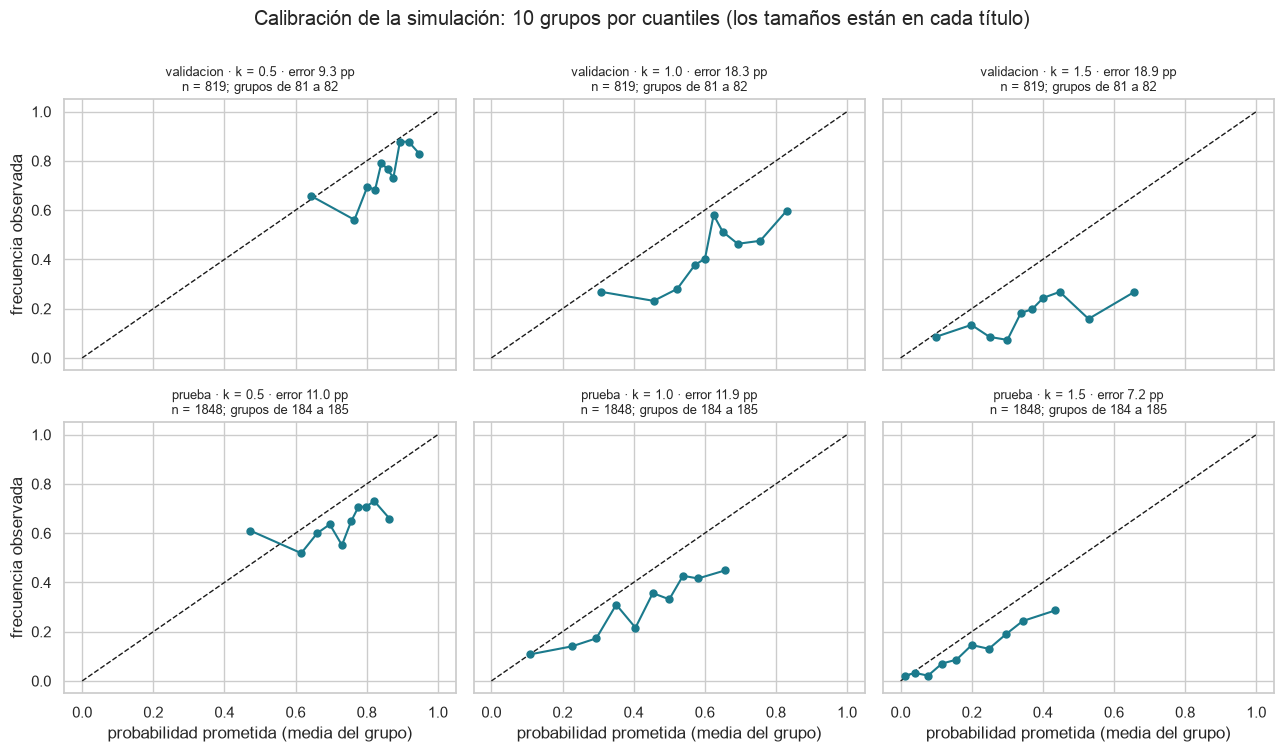

validacion k=0.5: prometido → [0.64, 0.77, 0.8, 0.82, 0.84, 0.86, 0.88, 0.89, 0.92, 0.95] 
               observado → [0.66, 0.56, 0.7, 0.68, 0.79, 0.77, 0.73, 0.88, 0.88, 0.83] · n = [82, 82, 82, 82, 82, 81, 82, 82, 82, 82]
validacion k=1.0: prometido → [0.31, 0.46, 0.52, 0.57, 0.6, 0.62, 0.65, 0.69, 0.76, 0.83] 
               observado → [0.27, 0.23, 0.28, 0.38, 0.4, 0.58, 0.51, 0.46, 0.48, 0.6] · n = [82, 82, 82, 82, 82, 81, 82, 82, 82, 82]
validacion k=1.5: prometido → [0.1, 0.2, 0.25, 0.3, 0.34, 0.37, 0.4, 0.45, 0.53, 0.66] 
               observado → [0.09, 0.13, 0.09, 0.07, 0.18, 0.2, 0.24, 0.27, 0.16, 0.27] · n = [82, 82, 82, 82, 82, 81, 82, 82, 82, 82]
prueba k=0.5: prometido → [0.47, 0.62, 0.66, 0.7, 0.73, 0.76, 0.78, 0.8, 0.82, 0.86] 
               observado → [0.61, 0.52, 0.6, 0.64, 0.55, 0.65, 0.71, 0.71, 0.73, 0.66] · n = [185, 185, 185, 184, 185, 185, 184, 185, 185, 185]
prueba k=1.0: prometido → [0.11, 0.23, 0.29, 0.35, 0.41, 0.45, 0.5, 0.54, 0.58, 0.66] 
            

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True, sharey=True)
for a, c in enumerate(CONJUNTOS_EVAL):
    for b, k in enumerate(K_EVAL):
        ax = axs[a, b]; e = evaluacion[c][str(float(k))]; t = pd.DataFrame(e["calibracion"])
        ax.plot([0, 1], [0, 1], "k--", lw=1); ax.plot(t.p_media, t.tasa_obs, "o-", color="#1b7a8c", ms=5)
        ax.set_title(f"{c} · k = {k} · error {e['error_calibracion_medio'] * 100:.1f} pp\nn = {e['n_origenes']}; grupos de {int(t.n.min())} a {int(t.n.max())}", fontsize=9)
        if a == 1: ax.set_xlabel("probabilidad prometida (media del grupo)")
        if b == 0: ax.set_ylabel("frecuencia observada")
plt.suptitle("Calibración de la simulación: 10 grupos por cuantiles (los tamaños están en cada título)", y=1.0); plt.tight_layout()
plt.savefig(cm.DIR_ASSETS_E2 / "nb08_calibracion.png", dpi=130); plt.show()
for c in CONJUNTOS_EVAL:
    for k in K_EVAL:
        t = pd.DataFrame(evaluacion[c][str(float(k))]["calibracion"])
        print(f"{c} k={k}: prometido →", np.round(t.p_media.to_numpy(), 2).tolist(), "\n               observado →", np.round(t.tasa_obs.to_numpy(), 2).tolist(), "· n =", t.n.tolist())

**Lectura.** Los grupos tienen entre 81 y 82 orígenes en validación y entre 184 y 185 en la prueba, así que cada punto resume decenas o cientos de casos (un grupo de 82 con frecuencia 0,5 tiene un error de muestreo cercano a ±0,11, por lo que las diferencias pequeñas entre grupos vecinos no son informativas). La forma es consistente: los grupos de mayor probabilidad quedan por debajo de la diagonal y los de menor probabilidad suelen estar más cerca de ella (con excepciones: en la prueba con k = 0,5 el grupo más bajo promete 0,47 y observa 0,61). En la prueba con k = 1,0, prometer 0,11 se observa 0,11 y prometer 0,23 se observa 0,14, pero prometer 0,58 se observa 0,42 y prometer 0,66 se observa 0,45; con k = 1,5, prometer 0,43 se observa 0,29. En validación con k = 1,0 el grupo que promete 0,83 observa 0,60. En todos los paneles la frecuencia observada **sube** con la probabilidad prometida (la simulación ordena razonablemente: AUC de la prueba 0,562; 0,661 y 0,733), pero el número absoluto exagera. Hay que leer una promesa de 60 % como "una cifra que históricamente se quedó por encima de lo observado", no como 60 % de frecuencia.

                   BSS                        n                   prob media               tasa obs              
k               0.5000  1.0000  1.5000   0.5000   1.0000   1.5000     0.5000 1.0000 1.5000   0.5000 1.0000 1.5000
conjunto   anio                                                                                                  
prueba     2019 0.0400  0.2900  0.3340 273.0000 273.0000 273.0000     0.7250 0.4020 0.1670   0.7440 0.3520 0.1100
           2020 0.1110  0.4870  0.4830 273.0000 273.0000 273.0000     0.6140 0.2580 0.0850   0.6300 0.2490 0.0700
           2021 0.1040  0.3040  0.2090 273.0000 273.0000 273.0000     0.7360 0.4390 0.2170   0.7770 0.3590 0.1540
           2022 0.2240  0.4570  0.4530 273.0000 273.0000 273.0000     0.7230 0.4070 0.1870   0.4730 0.1580 0.0370
           2023 0.2230  0.3930  0.3130 273.0000 273.0000 273.0000     0.7240 0.4100 0.1820   0.6190 0.2860 0.1500
           2024 0.1530  0.2400  0.1150 273.0000 273.0000 273.0000     0.7770 0.5230 0.29

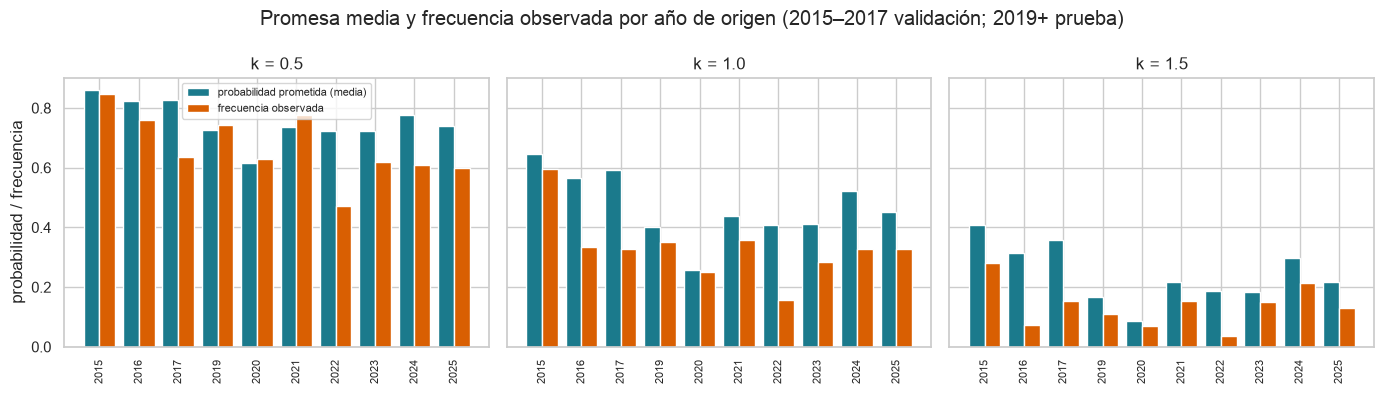


Por subperíodo (validación y prueba juntas; 2010–2012 queda sin orígenes evaluados):
              BSS                        n                     prob media               tasa obs              
k          0.5000 1.0000  1.5000    0.5000    1.0000    1.5000     0.5000 1.0000 1.5000   0.5000 1.0000 1.5000
subperiodo                                                                                                    
2013–2019  0.0580 0.1260 -0.0160 1092.0000 1092.0000 1092.0000     0.8090 0.5520 0.3110   0.7460 0.4020 0.1550
2020–2021  0.1090 0.3990  0.3320  546.0000  546.0000  546.0000     0.6750 0.3490 0.1510   0.7030 0.3040 0.1120
2022+      0.1990 0.3350  0.2540 1029.0000 1029.0000 1029.0000     0.7410 0.4480 0.2210   0.5730 0.2710 0.1320


In [10]:
# Por año de origen (validación y prueba): promesa media frente a frecuencia observada, Brier y BSS frente a la referencia del entrenamiento
eva["anio"] = eva.fecha.dt.year
filas = []
for (c, k, an), d in eva[eva.conjunto.isin(CONJUNTOS_EVAL)].groupby(["conjunto", "k", "anio"]):
    ref_k = tasa_ref[str(float(k))]
    filas.append({"conjunto": c, "k": k, "anio": int(an), "n": len(d), "prob media": d.prob.mean(), "tasa obs": d.y.mean(), "Brier": brier(d.prob, d.y),
                  "Brier ref": brier(np.full(len(d), ref_k), d.y), "BSS": cm.brier_skill(d.y.to_numpy(), d.prob.to_numpy(), ref_k)})
tab_a = pd.DataFrame(filas)
print(tab_a.pivot_table(index=["conjunto", "anio"], columns="k", values=["n", "prob media", "tasa obs", "BSS"]).round(3).to_string())
fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, k in zip(axs, K_EVAL):
    d = tab_a[tab_a.k == k].sort_values("anio"); x = np.arange(len(d))
    ax.bar(x - 0.2, d["prob media"], 0.4, label="probabilidad prometida (media)", color="#1b7a8c"); ax.bar(x + 0.2, d["tasa obs"], 0.4, label="frecuencia observada", color="#d95f02")
    ax.set_xticks(x); ax.set_xticklabels(d.anio.astype(str), rotation=90, fontsize=8); ax.set_title(f"k = {k}")
axs[0].legend(fontsize=8); axs[0].set_ylabel("probabilidad / frecuencia"); plt.suptitle("Promesa media y frecuencia observada por año de origen (2015–2017 validación; 2019+ prueba)"); plt.tight_layout()
plt.savefig(cm.DIR_ASSETS_E2 / "nb08_por_anio.png", dpi=130); plt.show()
# Por subperíodo (mismos rótulos que nb06/nb07; se agrupan por el año del origen; los de 2010–2012 son del entrenamiento y no se evalúan)
eva["subperiodo"] = eva.anio.map(lambda a: next(n for n, (lo, hi) in SUBPERIODOS.items() if lo <= a <= hi))
sub = []
for (s, k), d in eva[eva.conjunto.isin(CONJUNTOS_EVAL)].groupby(["subperiodo", "k"]):
    ref_k = tasa_ref[str(float(k))]
    sub.append({"subperiodo": s, "k": k, "n": len(d), "prob media": d.prob.mean(), "tasa obs": d.y.mean(), "BSS": cm.brier_skill(d.y.to_numpy(), d.prob.to_numpy(), ref_k)})
tab_s = pd.DataFrame(sub); print("\nPor subperíodo (validación y prueba juntas; 2010–2012 queda sin orígenes evaluados):")
print(tab_s.pivot_table(index="subperiodo", columns="k", values=["n", "prob media", "tasa obs", "BSS"]).round(3).to_string())
for c in CONJUNTOS_EVAL:
    for k in K_EVAL:
        evaluacion[c][str(float(k))]["por_anio"] = {str(int(a)): {"n": int(g.n), "prob_media": float(g["prob media"]), "tasa_obs": float(g["tasa obs"]), "brier": float(g.Brier), "bss": float(g.BSS)}
                                                   for a, g in tab_a[(tab_a.conjunto == c) & (tab_a.k == k)].set_index("anio").iterrows()}

**Lectura.** En la prueba, el BSS frente a la referencia es positivo en los siete años con k = 1,0 y k = 1,5 (de 0,115 a 0,487) y en todos con k = 0,5 (de 0,040 a 0,224), pero por la razón dicha: la referencia es vieja. La calibración sí cambia con el año: en 2020 la simulación promete 0,614; 0,258 y 0,085 y se observa 0,630; 0,249 y 0,070 (casi exacta), y en 2019 promete 0,725; 0,402; 0,167 y se observa 0,744; 0,352; 0,110; en cambio en **2022** promete 0,723; 0,407; 0,187 y se observa 0,473; 0,158; 0,037 (año de caídas: el pasado simulado no lo anticipaba). En 2023 a 2025 también promete de más (2024: 0,777 frente a 0,608 con k = 0,5; 0,523 frente a 0,326 con k = 1,0). En validación, con k = 1,5 el BSS es negativo en los tres años (−0,081; −0,042; −0,228), y con k = 1,0 en 2017 (−0,013). Por subperíodo (año del origen; el de 2010–2012 pertenece al entrenamiento y no se evalúa): 2013–2019 BSS 0,058; 0,126 y −0,016 (k = 0,5; 1,0; 1,5); 2020–2021: 0,109; 0,399; 0,332; 2022+: 0,199; 0,335; 0,254, con promesa media por encima de lo observado en todos los casos salvo k = 0,5 en 2020–2021 (0,675 prometido y 0,703 observado); por ejemplo, 2022+: 0,741 frente a 0,573 con k = 0,5. Las cifras por año son orientativas (273 orígenes de 21 acciones comparten el mismo año y el mismo mercado).

In [11]:
# Sensibilidad (sin decisión): bloque de SIMULACIÓN de 4 y 26 semanas en validación (el bloque de 12 es el principal).
# El bloque del bootstrap del IC no se cambia: 26 no es estimable de forma estable con ~39 fechas.
try:
    cm.ic_bootstrap_fechas(eva[(eva.conjunto == "validacion") & (eva.k == 1.0)], lambda x: x.y.mean(), bloque=26, reps=10)
    aviso_26 = "calculable, pero con 39 fechas es 1,5 bloques: no es estable y no se usa"
except ValueError as e:
    aviso_26 = str(e)
print("bootstrap del IC con bloque 26 en validación:", aviso_26)
val_ori = eva[(eva.conjunto == "validacion") & (eva.k == 1.0)][["fecha", "ticker"]].reset_index(drop=True)
idx_orig = {(tk, t): j for j, (tk, t) in enumerate((tk, t) for tk in cm.tickers() for t in fechas_origen)}
sens, sens_json = [], {}
for bl in (4, cm.SIM_BLOQUE_SEMANAS, 26):
    filas_b = []
    for tk, t in zip(val_ori.ticker, val_ori.fecha):
        P, sg, nvs, out = evaluar_origen(px[tk], px_xlp, t, bloque=bl, semilla=cm.SEMILLA + idx_orig[(tk, t)])
        fut = px[tk].loc[t:].iloc[1:H_EVAL + 1]
        for k, nv, p in zip(K_EVAL, nvs, out["prob"]): filas_b.append((tk, t, k, p, float(fut.max() >= nv)))
    db = pd.DataFrame(filas_b, columns=["ticker", "fecha", "k", "prob", "y"])
    for k in K_EVAL:
        d = db[db.k == k]; ref_k = tasa_ref[str(float(k))]
        sens.append({"bloque": bl, "k": k, "prob media": d.prob.mean(), "tasa obs": d.y.mean(), "Brier": brier(d.prob, d.y), "BSS": cm.brier_skill(d.y.to_numpy(), d.prob.to_numpy(), ref_k), "err cal": ece(d.prob, d.y)})
tab_sens = pd.DataFrame(sens); print(tab_sens.to_string(index=False))
sens_json = {str(b): {str(float(k)): {c: float(g[c].iloc[0]) for c in ["prob media", "tasa obs", "Brier", "BSS", "err cal"]} for k, g in gb.groupby("k")} for b, gb in tab_sens.groupby("bloque")}

bootstrap del IC con bloque 26 en validación: calculable, pero con 39 fechas es 1,5 bloques: no es estable y no se usa


 bloque      k  prob media  tasa obs  Brier     BSS  err cal
      4 0.5000      0.8190    0.7473 0.1891  0.0797   0.0734
      4 1.0000      0.5923    0.4188 0.2656  0.0790   0.1734
      4 1.5000      0.3677    0.1697 0.1866 -0.1257   0.1980
     12 0.5000      0.8368    0.7473 0.1924  0.0637   0.0927
     12 1.0000      0.6015    0.4188 0.2686  0.0686   0.1827
     12 1.5000      0.3591    0.1697 0.1854 -0.1182   0.1894
     26 0.5000      0.8580    0.7473 0.1979  0.0368   0.1181
     26 1.0000      0.5998    0.4188 0.2670  0.0741   0.1810
     26 1.5000      0.3376    0.1697 0.1804 -0.0884   0.1728


**Lectura.** Cambiar el bloque de simulación de 12 a 4 o 26 semanas mueve poco las conclusiones en validación: el BSS con k = 0,5 es 0,080; 0,064 y 0,037 (bloques de 4; 12 y 26), con k = 1,0 es 0,079; 0,069 y 0,074, y con k = 1,5 es −0,126; −0,118 y −0,088; el error de calibración va de 7,3 a 11,8 pp con k = 0,5, de 17,3 a 18,3 con k = 1,0 y de 17,3 a 19,8 con k = 1,5. La probabilidad media prometida cambia menos de 4 puntos entre bloques (0,819; 0,837 y 0,858 con k = 0,5). **El sesgo hacia arriba no depende del bloque.** Esta sensibilidad no lleva decisión. El bloque de 26 semanas no se usa en el bootstrap del IC: con 39 fechas serían 1,5 bloques y el IC no sería estable.

## 8. Qué se asocia con la sobreestimación: la deriva de la historia

La simulación repite trozos del pasado **con su rendimiento incluido**. Si ese pasado rindió más que el período que siguió, la promesa sale alta. Para mirarlo, en cada origen evaluable se calcula (a) el retorno anual medio de la historia usada (media de los log-retornos semanales hasta el origen, por 52) y (b) el retorno que se observó en las 52 semanas siguientes. Como diagnóstico, y sin tocar `simular_salidas`, se vuelve a simular con la historia **sin su media** (mismos niveles y semillas): es una cota inferior de lo que prometería si no hubiera deriva.

In [12]:
# Diagnóstico de la deriva (sin cambiar simular_salidas): ¿la historia que se remuestrea rindió más que el período siguiente?
# Para cada origen evaluable: retorno anualizado medio de la historia usada (media de los log-retornos semanales hasta t, × 52)
# y retorno que se observó después (log(P_{t+52} / P_t)). Además, la promesa con la historia "sin su media" (solo diagnóstico: mismos niveles y semillas).
orig_k = eva[eva.k == K_EVAL[0]][["fecha", "ticker", "conjunto"]].reset_index(drop=True)
hist_ret, post_ret, prob_sm = [], [], []
for tk, t in zip(orig_k.ticker, orig_k.fecha):
    pa = px[tk].loc[:t].dropna(); ra_t = np.log(pa).diff().dropna(); rx_t = np.log(px_xlp.loc[:t].dropna()).diff().dropna()
    hist_ret.append(float(ra_t.mean() * 52))
    post_ret.append(float(np.log(px[tk].loc[t:].iloc[H_EVAL] / px[tk].loc[t])))
    nvs = eva[(eva.ticker == tk) & (eva.fecha == t)].sort_values("k")["nivel"].tolist()
    o = cm.simular_salidas(ra_t - ra_t.mean(), rx_t, float(pa.iloc[-1]), nvs, semilla=cm.SEMILLA + idx_orig[(tk, t)])
    prob_sm.append(o["prob"].to_numpy())
orig_k["hist_anual"] = hist_ret; orig_k["post_anual"] = post_ret
for j, k in enumerate(K_EVAL): orig_k[f"prob_sm_{k}"] = [p[j] for p in prob_sm]
deriva, filas_d = {}, []
for c in ["entrenamiento"] + CONJUNTOS_EVAL:
    d = orig_k[orig_k.conjunto == c]; e = eva[eva.conjunto == c]
    fila = {"conjunto": c, "n_origenes": int(len(d)), "retorno_historia_anual": float(d.hist_anual.mean()), "retorno_posterior_anual": float(d.post_anual.mean())}
    for k in K_EVAL:
        ek = e[e.k == k]; kk = str(float(k))
        fila[f"k{kk}"] = {"prob_media": float(ek.prob.mean()), "prob_media_sin_media": float(d[f"prob_sm_{k}"].mean()), "tasa_obs": float(ek.y.mean())}
    deriva[c] = fila
    filas_d.append({"conjunto": c, "n": len(d), "hist anual": fila["retorno_historia_anual"], "posterior anual": fila["retorno_posterior_anual"],
                    **{f"{x} k={k}": fila[f"k{float(k)}"][y] for k in K_EVAL for x, y in (("prom", "prob_media"), ("sin media", "prob_media_sin_media"), ("obs", "tasa_obs"))}})
print(pd.DataFrame(filas_d).T.to_string(header=False))
res["deriva"] = deriva

conjunto         entrenamiento  validacion  prueba
n                          840         819    1848
hist anual              0.1595      0.1551  0.1240
posterior anual         0.1769      0.0716  0.0610
prom k=0.5              0.8615      0.8368  0.7192
sin media k=0.5         0.5909      0.5459  0.4793
obs k=0.5               0.8762      0.7473  0.6369
prom k=1.0              0.6571      0.6015  0.4117
sin media k=1.0         0.2900      0.2459  0.1905
obs k=1.0               0.6310      0.4188  0.2927
prom k=1.5              0.4302      0.3591  0.1926
sin media k=1.5         0.1184      0.0918  0.0656
obs k=1.5               0.3274      0.1697  0.1228


**Lectura.** En el entrenamiento la historia y el futuro coinciden (retorno anual medio de 0,160 en la historia y 0,177 después) y la promesa casi acierta (0,862 frente a 0,876 observado con k = 0,5). En validación la historia rindió 0,155 al año y el período siguiente 0,072; en la prueba, 0,124 y 0,061: **la sobreestimación se asocia con que la historia remuestreada tuvo más rendimiento que el período siguiente**. Al quitar la media de la historia, la promesa pasa de 0,837; 0,602 y 0,359 a 0,546; 0,246 y 0,092 en validación (observado: 0,747; 0,419 y 0,170), y de 0,719; 0,412 y 0,193 a 0,479; 0,191 y 0,066 en la prueba (observado: 0,637; 0,293 y 0,123). Es decir, **quitar la deriva corrige de más** (promete menos de lo observado; en el entrenamiento, donde la historia sí era buen guía, quedaría en 0,591; 0,290 y 0,118 frente a 0,876; 0,631 y 0,327). **Ninguna de las dos versiones está calibrada:** la verdad queda entre ambas, y cuánta deriva conservar es una pregunta abierta (ver oportunidades de mejora).

## 9. Qué se concluye y qué se guarda

Se contrasta la probabilidad prometida con la observada, se declaran las limitaciones y se guardan las cifras en `data/resultados/nb08.json`.

In [13]:
# Contraste de la probabilidad prometida con la frecuencia observada y guardado
pru = {k: evaluacion["prueba"][k] for k in KS}; vl = {k: evaluacion["validacion"][k] for k in KS}
for c in CONJUNTOS_EVAL:
    for k in KS:
        e = evaluacion[c][k]
        print(f"{c:10s} k={k}: prometido {e['prob_media']:.3f} · observado {e['tasa_obs']:.3f} · BSS {e['bss']:+.3f} (IC95 {e['ic']['bss'][1]:+.3f} a {e['ic']['bss'][2]:+.3f}) · "
              f"error de calibración {e['error_calibracion_medio'] * 100:.1f} pp (IC95 {e['ic']['error_calibracion_medio'][1] * 100:.1f} a {e['ic']['error_calibracion_medio'][2] * 100:.1f}) "
              f"→ {'por debajo' if e['error_calibracion_medio'] <= CRITERIO_CALIB else 'por encima'} de {CRITERIO_CALIB * 100:.0f} pp")
constantes = {"K_EVAL": list(K_EVAL), "H_EVAL": H_EVAL, "MIN_HIST_SEM_SIM": MIN_HIST_SEM_SIM, "PASO_ORIGEN_SEM": PASO_ORIGEN_SEM, "BLOQUE_IC_FECHAS": BLOQUE_IC_FECHAS,
              "N_SUBLOTES_IC": N_SUBLOTES_IC, "CRITERIO_CALIB": CRITERIO_CALIB, "SIM_BLOQUE_SEMANAS": cm.SIM_BLOQUE_SEMANAS, "SIM_REPS": cm.SIM_REPS,
              "SIM_REPS_RF11": cm.SIM_REPS_RF11, "SIM_HORIZONTE_SEMANAS": cm.SIM_HORIZONTE_SEMANAS, "SEMILLA": cm.SEMILLA, "REPS_BOOT": cm.REPS_BOOT}
res.update({"constantes": constantes, "tasa_ref_entrenamiento": tasa_ref, "evaluacion_simulacion": evaluacion, "sensibilidad_bloque_validacion": sens_json,
            "bootstrap_bloque_26": aviso_26, "por_subperiodo": json.loads(tab_s.to_json(orient="records")), "tiempo_ejecucion_min": round((time.time() - T0) / 60, 1)})
def limpio(o):                                         # NaN → null y numpy → tipos de JSON, también dentro de listas
    if isinstance(o, dict): return {str(k): limpio(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)): return [limpio(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else float(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
cm.DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
destino = cm.DIR_RESULTADOS / "nb08.json"
destino.write_text(json.dumps(limpio(res), ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print(f"Escrito: {destino.name} — claves: {list(res)}"); print(f"Tiempo total de ejecución: {res['tiempo_ejecucion_min']} min")

validacion k=0.5: prometido 0.837 · observado 0.747 · BSS +0.064 (IC95 +0.022 a +0.118) · error de calibración 9.3 pp (IC95 2.9 a 16.7) → por encima de 5 pp
validacion k=1.0: prometido 0.602 · observado 0.419 · BSS +0.069 (IC95 +0.030 a +0.160) · error de calibración 18.3 pp (IC95 12.3 a 24.7) → por encima de 5 pp
validacion k=1.5: prometido 0.359 · observado 0.170 · BSS -0.118 (IC95 -0.166 a -0.022) · error de calibración 18.9 pp (IC95 15.7 a 24.1) → por encima de 5 pp
prueba     k=0.5: prometido 0.719 · observado 0.637 · BSS +0.160 (IC95 +0.082 a +0.227) · error de calibración 11.0 pp (IC95 6.1 a 17.5) → por encima de 5 pp
prueba     k=1.0: prometido 0.412 · observado 0.293 · BSS +0.348 (IC95 +0.252 a +0.475) · error de calibración 11.9 pp (IC95 8.1 a 18.4) → por encima de 5 pp
prueba     k=1.5: prometido 0.193 · observado 0.123 · BSS +0.288 (IC95 +0.166 a +0.450) · error de calibración 7.2 pp (IC95 4.1 a 10.8) → por encima de 5 pp
Escrito: nb08.json — claves: ['verificacion_funcion'

**Qué se concluye (evaluación de un procedimiento, sin H0/H1).**
- **Calibración:** la simulación **se aparta de la diagonal** en el mismo sentido en todos los k y conjuntos: promete más de lo que se observó. En la prueba, 8,2 pp con k = 0,5 (promete 71,9 %, observa 63,7 %), 11,9 pp con k = 1,0 (41,2 % frente a 29,3 %) y 7,0 pp con k = 1,5 (19,3 % frente a 12,3 %); en validación, 9,0; 18,3 y 18,9 pp. El error de calibración medio (7,2 a 18,9 pp) queda por encima de la referencia descriptiva de 5 pp en los seis casos.
- **Brier:** frente a la tasa constante del entrenamiento el BSS es positivo en la prueba (0,160; 0,348; 0,288, con IC95 por encima de 0) y mixto en validación (0,064; 0,069 y −0,118 con k = 1,5, este último con IC por debajo de 0). La referencia se quedó vieja, así que esto muestra que la simulación se adapta a cada acción mejor que un número fijo, no que esté bien calibrada. Dos decisiones, según la plantilla del curso: **estadística**, el IC95 del BSS de la prueba excluye 0 en los tres k; **de negocio**, el producto no depende de acertar el porcentaje, sino de que el inversor sepa cuánto creerle: con un error de calibración de 7 a 12 pp en la prueba, **la lectura probabilística se presenta como informativa**, con la calibración histórica a la vista y la regla "la frecuencia observada fue menor que la prometida".
- **Estabilidad:** la promesa supera lo observado en cada año de validación (2015–2017, los tres k) y en 2022–2025 de la prueba; en 2019–2021 queda cerca de la observada (con k = 0,5 incluso por debajo: 0,725 frente a 0,744 en 2019). Es un resultado coherente con el cambio de régimen de volatilidad del notebook 06 y con que la técnica del notebook 07 no superó su línea base: no hay lectura del producto cuya cifra absoluta sea precisa. La sección de la deriva muestra con qué se asocia el sesgo (asociación, no causa).

**Limitaciones.** (1) Los orígenes se solapan (52 semanas) y las 21 acciones comparten año y mercado: por eso el IC es por bloques de fechas, y aun así 39 fechas de validación dan solo 3 bloques (IC orientativo; la decisión se apoya en la prueba). (2) Un solo sector (consumo defensivo): no se generaliza a otros. (3) La serie incluye los dividendos reinvertidos mientras el nivel del usuario es un precio nominal, lo cual sobrestima algo la probabilidad en acciones de alto dividendo. (4) La trayectoria usa cierres **semanales**: un nivel que se toca a mitad de semana y se pierde antes del cierre no cuenta. (5) 2018 queda fuera de la validación por la brecha de 52 semanas. (6) La referencia es una tasa de 2011–2013: fijarla antes de ver los resultados evita el sesgo de elección, pero la deja lejos del periodo siguiente. (7) La probabilidad usa solo la historia de la acción; el XLP no cambia la cifra. (8) **Sesgo de supervivencia:** las 21 acciones son empresas que existen hoy con historia desde 2009; no hay datos de empresas que salieron del sector, así que no se puede cifrar, pero va en el sentido de promesas más altas. (9) Los bloques móviles **sin envolver** dan menos peso a las últimas 11 semanas de la historia (la semana final entra en 1 de los 12 inicios posibles y las del centro en 12); con unas 573 semanas o más el efecto es pequeño. (10) Si los retornos cayeran exactamente sobre una malla, la comparación en coma flotante podría no contar un alcance exacto; con retornos continuos no ocurre y se deja como nota.

**Oportunidades de mejora (a validar en el futuro; no cambian `simular_salidas` ni el producto).** Una deriva intermedia (por ejemplo, la mitad de la media histórica) o una deriva reciente (solo la media de los últimos años) podrían quedar entre las dos versiones de la sección anterior; habría que elegirlas con la validación y medirlas una sola vez en la prueba, y ninguna se probó aquí. También quedan por explorar bloques circulares y un horizonte o un bloque distintos.

**Trazabilidad.** Cada cifra de este texto sale de una celda ejecutada y se guarda en `data/resultados/nb08.json` (`evaluacion_simulacion`, `constantes`, `lookahead_sim_ok`, `n_brecha_simulacion`, `tiempo_llamada_ms`).